# Notebook 04 -- Entrenamiento SCE-Net

Entrenamiento completo del modelo SCE-Net con la configuracion exacta del paper:
- **Optimizador**: Adam con learning rates diferenciados
  - Backbone ResNet18: lr=5e-5 (preentrenado, actualizacion lenta)
  - Masks + Weight Branch: lr=5e-4 (capas nuevas, actualizacion rapida)
- **Batch size**: 64
- **Early stopping** basado en triplet loss de validacion
- **Checkpoints** del mejor modelo

Referencia configuracion: Vasileva et al. (ECCV 2018), citado en seccion 4.2 del paper.

In [1]:
# Liberar memoria GPU antes de empezar
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# Verificar después
free = (torch.cuda.get_device_properties(0).total_memory - 
        torch.cuda.memory_reserved(0)) / 1e9
print(f'VRAM libre tras limpiar: {free:.1f} GB')

VRAM libre tras limpiar: 6.4 GB


In [2]:
import torch

if torch.cuda.is_available():
    total   = torch.cuda.get_device_properties(0).total_memory / 1e9
    reserv  = torch.cuda.memory_reserved(0) / 1e9
    alloc   = torch.cuda.memory_allocated(0) / 1e9
    free    = total - reserv
    print(f'GPU              : {torch.cuda.get_device_name(0)}')
    print(f'VRAM total       : {total:.1f} GB')
    print(f'VRAM reservada   : {reserv:.1f} GB')
    print(f'VRAM asignada    : {alloc:.1f} GB')
    print(f'VRAM libre       : {free:.1f} GB')
else:
    print('No hay GPU disponible')

GPU              : NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM total       : 6.4 GB
VRAM reservada   : 0.0 GB
VRAM asignada    : 0.0 GB
VRAM libre       : 6.4 GB


## Configuracion

In [3]:
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import json
import time
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from tqdm.notebook import tqdm

# Rutas
OUT_DIR   = Path('./polyvore_kaggle/polyvore_outfits/data/processed')
DATA_ROOT = Path('./polyvore_kaggle')
CKPT_DIR  = Path('./checkpoints')
CKPT_DIR.mkdir(exist_ok=True)

# Cargar configuracion del modelo
with open(OUT_DIR / 'model_config.json') as f:
    cfg = json.load(f)

EMBED_DIM    = cfg['embed_dim']       # 64
M_CONDITIONS = cfg['m_conditions']    # 5
TEXT_DIM     = cfg['text_dim']        # 2048
IMG_SIZE     = cfg['img_size']        # 224
MARGIN    = 0.2    # era 0.3, más margen fuerza separación mayor
LAMBDA_L1 = 5e-4   # era 5e-4, más L1 penaliza más las máscaras dominantes
LAMBDA_L2 = 5e-4   # sin cambio
# LAMBDA_VSE = 5e-4   # valores del paper: misma escala que triplet
LAMBDA_SIM = 5e-4
LAMBDA_DIV   = 0.5   # nuevo — penaliza colapso de condiciones

# Hiperparametros de entrenamiento (paper: Vasileva et al.)
BATCH_SIZE   = 128
LR_BACKBONE  = 2.5e-5   # learning rate ResNet18 (preentrenado)
LR_OTHER     = 2.5e-4   # learning rate masks + weight branch (capas nuevas)
NUM_EPOCHS   = 50
PATIENCE     = 5      # early stopping: epocas sin mejora
NUM_WORKERS  = 0      # workers para Data

cfg['margin']      = MARGIN
cfg['lambda_l1']   = LAMBDA_L1
cfg['lambda_l2']   = LAMBDA_L2
# cfg['lambda_vse']  = LAMBDA_VSE
cfg['lambda_sim']  = LAMBDA_SIM
cfg['lambda_div']  = LAMBDA_DIV

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Dispositivo  : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU          : {torch.cuda.get_device_name(0)}')
    print(f'VRAM         : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print(f'BATCH_SIZE   : {BATCH_SIZE}')
print(f'LR backbone  : {LR_BACKBONE}')
print(f'LR other     : {LR_OTHER}')
print(f'NUM_EPOCHS   : {NUM_EPOCHS}')
print(f'PATIENCE     : {PATIENCE}')


Dispositivo  : cuda
GPU          : NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM         : 6.4 GB
BATCH_SIZE   : 128
LR backbone  : 2.5e-05
LR other     : 0.00025
NUM_EPOCHS   : 50
PATIENCE     : 5


## 1. Definicion del modelo (copia desde notebook 03)

Replicamos aqui las clases del modelo para que este notebook sea autocontenido.

In [4]:
from torchvision import models as tv_models

# ── ResNet18 Backbone ───────────────────────────────────────────
class ResNet18Backbone(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        base           = tv_models.resnet18(weights=tv_models.ResNet18_Weights.IMAGENET1K_V1)
        self.features  = nn.Sequential(*list(base.children())[:-1])
        self.projection = nn.Linear(512, embed_dim, bias=False)

    # def forward(self, x):
    #     feat = self.features(x).flatten(1)
    #     return F.normalize(self.projection(feat), p=2, dim=-1)


# ── Condition Masks ─────────────────────────────────────────────
class ConditionMasks(nn.Module):
    def __init__(self, m_conditions, embed_dim):
        super().__init__()
        self.masks = nn.Parameter(torch.rand(m_conditions, embed_dim))

    def forward(self, v):
        return v.unsqueeze(1) * self.masks.unsqueeze(0)  # (B, M, D)

    def l1_loss(self):
        return self.masks.abs().sum()


# ── Condition Weight Branch ──────────────────────────────────────
class ConditionWeightBranch(nn.Module):
    def __init__(self, m_conditions, embed_dim, text_dim, hidden_dim=None, temperature=1.0):
    # def __init__(self, m_conditions, embed_dim, text_dim, hidden_dim=None):
        super().__init__()
        self.text_proj = nn.Sequential(
            nn.Linear(text_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, embed_dim),
            nn.ReLU(),
        )
        hidden = hidden_dim or max(2 * embed_dim, 64)
        self.mlp = nn.Sequential(
            nn.Linear(2 * embed_dim, hidden), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden, hidden),        nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden, m_conditions),
        )
        self.temperature = temperature

    def forward(self, v_i, v_j, t_i, t_j):
        vt_i   = v_i * self.text_proj(t_i)
        vt_j   = v_j * self.text_proj(t_j)
        logits = self.mlp(torch.cat([vt_i, vt_j], dim=-1))
        return F.softmax(logits / self.temperature, dim=-1)

    # def forward(self, v_i, v_j, t_i, t_j):
    #     vt_i = v_i * self.text_proj(t_i)
    #     vt_j = v_j * self.text_proj(t_j)
    #     return F.softmax(self.mlp(torch.cat([vt_i, vt_j], dim=-1)), dim=-1)


# ── SCE-Net ─────────────────────────────────────────────────────
class SCENet(nn.Module):
    def __init__(self, embed_dim, m_conditions, text_dim, img_size=224, temperature=1.0):
    # def __init__(self, embed_dim, m_conditions, text_dim, img_size=224):
        super().__init__()
        self.backbone      = ResNet18Backbone(embed_dim)
        self.cond_masks    = ConditionMasks(m_conditions, embed_dim)
        self.weight_branch = ConditionWeightBranch(m_conditions, embed_dim, text_dim, temperature=temperature)
        # self.weight_branch = ConditionWeightBranch(m_conditions, embed_dim, text_dim)

    def encode(self, img):
        feat = self.backbone.features(img).flatten(1)  # sin normalizar
        v_raw = self.backbone.projection(feat)          # sin normalizar
        v_norm = F.normalize(v_raw, p=2, dim=-1)        # normalizado
        return v_norm, v_raw                             # devolver ambos

    def get_final_embedding(self, v_i, v_j, t_i, t_j):
        w   = self.weight_branch(v_i, v_j, t_i, t_j)
        O_i = self.cond_masks(v_i)
        O_j = self.cond_masks(v_j)
        w_e = w.unsqueeze(-1)
        E_i = (w_e * O_i).sum(1)
        E_j = (w_e * O_j).sum(1)
        return F.normalize(E_i, p=2, dim=-1), F.normalize(E_j, p=2, dim=-1)
    
    def forward(self, img_a, img_p, img_n, txt_a, txt_p, txt_n):
        v_a, v_a_raw = self.encode(img_a)   # desempaquetar
        v_p, v_p_raw = self.encode(img_p)
        v_n, v_n_raw = self.encode(img_n)
        E_a1, E_p = self.get_final_embedding(v_a, v_p, txt_a, txt_p)
        E_a2, E_n = self.get_final_embedding(v_a, v_n, txt_a, txt_n)
        return (E_a1 + E_a2) / 2.0, E_p, E_n, v_a_raw, v_p_raw, v_n_raw


# ── Loss functions ───────────────────────────────────────────────
def triplet_loss(E_a, E_p, E_n, margin=MARGIN):
    d_pos = (E_a - E_p).norm(dim=-1)
    d_neg = (E_a - E_n).norm(dim=-1)
    return F.relu(d_pos - d_neg + margin).mean()

# def semi_hard_triplet_loss(E_a, E_p, E_n, margin=MARGIN):
#     d_pos = (E_a - E_p).norm(dim=-1)
#     d_neg = (E_a - E_n).norm(dim=-1)
    
#     # Semi-hard: negativos dentro del margen pero más lejos que el positivo
#     semi_hard = (d_neg > d_pos) & (d_neg < d_pos + margin)
    
#     loss = F.relu(d_pos - d_neg + margin)
    
#     if semi_hard.sum() > 0:
#         return loss[semi_hard].mean()
#     return loss.mean()

def l2_reg(v):
    return (v ** 2).sum(dim=-1).mean()

# def vse_loss(v_a, v_p, v_n, t_a, t_p, t_n, margin=0.2):
#     """
#     Visual-Semantic Embedding loss.
#     Cada imagen debe estar más cerca de su propio texto que del texto ajeno.
    
#     v_* : embeddings visuales (B, D)
#     t_* : embeddings de texto proyectados (B, D)
#     """
#     # Proyectar texto al mismo espacio que los embeddings visuales
#     # Normalizar ambos para comparación coseno
#     v_a_n = F.normalize(v_a, p=2, dim=-1)
#     v_p_n = F.normalize(v_p, p=2, dim=-1)
#     v_n_n = F.normalize(v_n, p=2, dim=-1)
#     t_a_n = F.normalize(t_a, p=2, dim=-1)
#     t_p_n = F.normalize(t_p, p=2, dim=-1)
#     t_n_n = F.normalize(t_n, p=2, dim=-1)

#     # Distancia imagen-texto propio vs imagen-texto ajeno
#     # Anchor
#     d_a_ta = (v_a_n - t_a_n).norm(dim=-1)  # imagen_a ↔ texto_a (debería ser pequeña)
#     d_a_tp = (v_a_n - t_p_n).norm(dim=-1)  # imagen_a ↔ texto_p (debería ser grande)
#     d_a_tn = (v_a_n - t_n_n).norm(dim=-1)  # imagen_a ↔ texto_n

#     # Positive
#     d_p_tp = (v_p_n - t_p_n).norm(dim=-1)
#     d_p_ta = (v_p_n - t_a_n).norm(dim=-1)

#     # Negative
#     d_n_tn = (v_n_n - t_n_n).norm(dim=-1)
#     d_n_ta = (v_n_n - t_a_n).norm(dim=-1)

#     l = (F.relu(d_a_ta - d_a_tp + margin) +
#          F.relu(d_a_ta - d_a_tn + margin) +
#          F.relu(d_p_tp - d_p_ta + margin) +
#          F.relu(d_n_tn - d_n_ta + margin))

#     return l.mean()


def sim_loss(v_a, v_p, v_n, margin=0.2):
    """
    Similarity loss.
    Items del mismo outfit (anchor-positive) deben estar más cerca
    entre sí que con el negativo.
    Opera sobre embeddings visuales crudos (antes de máscaras).
    """
    v_a_n = F.normalize(v_a, p=2, dim=-1)
    v_p_n = F.normalize(v_p, p=2, dim=-1)
    v_n_n = F.normalize(v_n, p=2, dim=-1)

    d_pos = (v_a_n - v_p_n).norm(dim=-1)  # anchor ↔ positive (mismo outfit)
    d_neg = (v_a_n - v_n_n).norm(dim=-1)  # anchor ↔ negative (distinto outfit)

    return F.relu(d_pos - d_neg + margin).mean()

def diversity_loss(w, min_entropy=1.0):
    """
    Penaliza solo cuando la entropía cae por debajo de min_entropy.
    No fuerza distribución uniforme — permite especialización.
    """
    entropy = -(w * (w + 1e-8).log()).sum(dim=-1).mean()
    return F.relu(min_entropy - entropy)

def total_loss(model, E_a, E_p, E_n, v_a, v_p, v_n, t_a, t_p, t_n):
    l_t   = triplet_loss(E_a, E_p, E_n)
    l_l1  = model.cond_masks.l1_loss()
    l_l2  = (l2_reg(v_a) + l2_reg(v_p) + l2_reg(v_n)) / 3.0
    l_sim = sim_loss(v_a, v_p, v_n)

    w_ap  = model.weight_branch(v_a, v_p, t_a, t_p)
    w_an  = model.weight_branch(v_a, v_n, t_a, t_n)
    l_div = (diversity_loss(w_ap) + diversity_loss(w_an)) / 2.0

    loss = (l_t
            + LAMBDA_L1 * l_l1
            + LAMBDA_L2 * l_l2
            + LAMBDA_SIM * l_sim
            + LAMBDA_DIV * l_div)

    return loss, l_t, l_l1, l_l2, l_sim, l_div


print('Clases del modelo definidas OK')

Clases del modelo definidas OK


## 2. Dataset y DataLoader

Dataset PyTorch que carga tripletas bajo demanda:
- Lee la imagen del disco y aplica las transformaciones
- Recupera el Fisher Vector de la matriz precargada en RAM
- Devuelve (img_a, img_p, img_n, txt_a, txt_p, txt_n)

In [5]:
# Transformaciones ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.Resize(IMG_SIZE + 32),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    # transforms.ColorJitter(
    #     brightness=0.2,
    #     contrast=0.2,
    #     saturation=0.2,
    #     hue=0.02,
    # ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

transform_val = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class TripletDataset(Dataset):
    """
    Dataset de tripletas (anchor, positive, negative).

    Carga imagenes del disco bajo demanda y recupera
    Fisher Vectors de una matriz precargada en RAM.
    """
    def __init__(self, triplets, item_index, fisher_matrix,
                 fv_lookup, data_root, transform, text_dim):
        self.triplets      = triplets
        self.item_index    = item_index
        self.fisher_matrix = fisher_matrix
        self.fv_lookup     = fv_lookup
        self.data_root     = Path(data_root)
        self.transform     = transform
        self.text_dim      = text_dim
        self.zero_fv       = np.zeros(text_dim, dtype=np.float32)

    def __len__(self):
        return len(self.triplets)

    def _load_image(self, item_id):
        img_path = self.data_root / 'polyvore_outfits' / self.item_index[item_id]['image_path']
        img      = Image.open(img_path).convert('RGB')
        return self.transform(img)

    def _get_fv(self, item_id):
        if item_id in self.fv_lookup:
            return self.fisher_matrix[self.fv_lookup[item_id]]
        return self.zero_fv

    def __getitem__(self, idx):
        t = self.triplets[idx]
        a_id = t['anchor_id']
        p_id = t['pos_id']
        n_id = t['neg_id']

        img_a = self._load_image(a_id)
        img_p = self._load_image(p_id)
        img_n = self._load_image(n_id)

        txt_a = torch.tensor(self._get_fv(a_id), dtype=torch.float32)
        txt_p = torch.tensor(self._get_fv(p_id), dtype=torch.float32)
        txt_n = torch.tensor(self._get_fv(n_id), dtype=torch.float32)

        return img_a, img_p, img_n, txt_a, txt_p, txt_n


# Cargar datos
print('Cargando datos...')

with open(OUT_DIR / 'item_index_full_nondisjoint.json') as f:
    item_index = json.load(f)

fisher_matrix = np.load(OUT_DIR / 'fisher_vectors_nondisjoint.npy')
with open(OUT_DIR / 'fisher_item_ids_nondisjoint.json') as f:
    fisher_ids = json.load(f)
fv_lookup = {iid: idx for idx, iid in enumerate(fisher_ids)}

with open(OUT_DIR / 'triplets_train_nondisjoint.json') as f:
    triplets_train = json.load(f)
with open(OUT_DIR / 'triplets_valid_nondisjoint.json') as f:
    triplets_valid = json.load(f)

print(f'Tripletas train : {len(triplets_train):,}')
print(f'Tripletas valid : {len(triplets_valid):,}')
print(f'Fisher Vectors  : {fisher_matrix.shape}')

# Crear datasets
dataset_train = TripletDataset(
    triplets_train, item_index, fisher_matrix,
    fv_lookup, DATA_ROOT, transform_train, TEXT_DIM)

dataset_valid = TripletDataset(
    triplets_valid, item_index, fisher_matrix,
    fv_lookup, DATA_ROOT, transform_val, TEXT_DIM)

MAX_TRIPLETS_PER_EPOCH = 200_000   # ~780 batches de 32

sampler_train = torch.utils.data.RandomSampler(
    dataset_train,
    replacement = False,
    num_samples = min(MAX_TRIPLETS_PER_EPOCH, len(dataset_train))
)

loader_train = DataLoader(
    dataset_train,
    batch_size  = BATCH_SIZE,
    sampler     = sampler_train,
    num_workers = 0,
    pin_memory  = True,
    drop_last   = True,
)

loader_valid = DataLoader(
    dataset_valid,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = True,
)

print(f'\nBatches por epoca (train): {len(loader_train):,}')
print(f'Batches por epoca (valid): {len(loader_valid):,}')

# Test rapido del dataloader
batch = next(iter(loader_train))
img_a, img_p, img_n, txt_a, txt_p, txt_n = batch
print(f'\nTest batch:')
print(f'  img_a : {img_a.shape}')
print(f'  txt_a : {txt_a.shape}')
print('DataLoader OK')


Cargando datos...
Tripletas train : 611,007
Tripletas valid : 57,223
Fisher Vectors  : (251008, 2048)

Batches por epoca (train): 1,562
Batches por epoca (valid): 448

Test batch:
  img_a : torch.Size([128, 3, 224, 224])
  txt_a : torch.Size([128, 2048])
DataLoader OK


In [6]:
import pickle
with open(OUT_DIR / 'gmm_model.pkl', 'rb') as f:
    gmm = pickle.load(f)

print(f'K (componentes GMM): {gmm.n_components}')
print(f'Converged          : {gmm.converged_}')
print(f'Lower bound final  : {gmm.lower_bound_:.4f}')

# Ver si los pesos del GMM están balanceados
print(f'\nPesos GMM (min/max/std):')
print(f'  min: {gmm.weights_.min():.4f}')
print(f'  max: {gmm.weights_.max():.4f}')
print(f'  std: {gmm.weights_.std():.4f}')
# Si max >> min, el GMM está colapsado en pocas componentes

K (componentes GMM): 64
Converged          : True
Lower bound final  : 246.8670

Pesos GMM (min/max/std):
  min: 0.0001
  max: 0.1635
  std: 0.0284


In [7]:
# ¿Cuántas palabras tienen los textos de los items?
import re

def tokenize(text):
    return [t for t in re.findall(r'[a-z]+', text.lower()) if len(t) > 2]

lengths = [len(tokenize(v['text'])) for v in item_index.values()]
n_empty = sum(1 for l in lengths if l == 0)
n_short = sum(1 for l in lengths if 0 < l <= 3)

print(f'Longitud media  : {np.mean(lengths):.1f} palabras')
print(f'Longitud mediana: {np.median(lengths):.1f} palabras')
print(f'Sin texto       : {n_empty:,} ({n_empty/len(lengths)*100:.1f}%)')
print(f'1-3 palabras    : {n_short:,} ({n_short/len(lengths)*100:.1f}%)')
print(f'Distribución    :')
for threshold in [1, 3, 5, 10, 20]:
    n = sum(1 for l in lengths if l <= threshold)
    print(f'  <= {threshold:2d} palabras: {n:,} ({n/len(lengths)*100:.1f}%)')

Longitud media  : 15.7 palabras
Longitud mediana: 5.0 palabras
Sin texto       : 396 (0.2%)
1-3 palabras    : 21,040 (8.4%)
Distribución    :
  <=  1 palabras: 1,920 (0.8%)
  <=  3 palabras: 21,436 (8.5%)
  <=  5 palabras: 161,390 (64.3%)
  <= 10 palabras: 179,168 (71.4%)
  <= 20 palabras: 190,236 (75.8%)


## 3. Instanciar modelo y optimizador

Dos grupos de parametros con learning rates distintos (paper: Vasileva et al.):
- **Backbone ResNet18**: lr=5e-5 (preentrenado en ImageNet, actualizacion lenta)
- **Condition masks + Weight branch**: lr=5e-4 (capas nuevas, actualizacion rapida)

In [ ]:
# Instanciar modelo
model = SCENet(
    embed_dim    = EMBED_DIM,
    m_conditions = M_CONDITIONS,
    text_dim     = TEXT_DIM,
    img_size     = IMG_SIZE,
    temperature  = 0.1,  # temperatura para suavizar pesos de condiciones
).to(DEVICE)

# Cargar pesos iniciales guardados en notebook 03
# init_path = OUT_DIR / 'sce_net_init.pth'
# if init_path.exists():
#     model.load_state_dict(torch.load(init_path, map_location=DEVICE))
#     print('Pesos iniciales cargados desde sce_net_init.pth')

# Optimizador con dos grupos de learning rate
# optimizer = torch.optim.Adam([
#     {'params': model.backbone.parameters(),      'lr': LR_BACKBONE, 'weight_decay': 1e-5},
#     {'params': model.cond_masks.parameters(),    'lr': LR_OTHER,    'weight_decay': 1e-4},
#     {'params': model.weight_branch.parameters(), 'lr': LR_OTHER,    'weight_decay': 1e-4},
# ])

optimizer = torch.optim.Adam([
    {'params': model.backbone.parameters()},
    {'params': model.cond_masks.parameters()},
    {'params': model.weight_branch.parameters()},
])

# Learning rate scheduler: reduce lr x0.1 si no mejora en 3 epocas
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode     = 'min',
    factor   = 0.1,
    patience = 3,
    verbose  = True,
)

print(f'Modelo en dispositivo: {next(model.parameters()).device}')
print(f'\nGrupos de parametros del optimizador:')
print(f'  Backbone      : lr={LR_BACKBONE}  params={sum(p.numel() for p in model.backbone.parameters()):,}')
print(f'  Cond. masks   : lr={LR_OTHER}  params={sum(p.numel() for p in model.cond_masks.parameters()):,}')
print(f'  Weight branch : lr={LR_OTHER}  params={sum(p.numel() for p in model.weight_branch.parameters()):,}')

Modelo en dispositivo: cuda:0

Grupos de parametros del optimizador:
  Backbone      : lr=2.5e-05  params=11,209,280
  Cond. masks   : lr=0.00025  params=320
  Weight branch : lr=0.00025  params=1,115,589


c:\Users\angel\Desktop\Viu\TFM\tfmvenv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [9]:
with open(DATA_ROOT / 'polyvore_outfits' / 'data/processed/triplets_train_nondisjoint.json') as f:
    triplets = json.load(f)

same_cat = 0
for t in triplets[:5000]:
    cat_a = item_index.get(str(t['anchor_id']), {}).get('category', '')
    cat_n = item_index.get(str(t['neg_id']),    {}).get('category', '')
    if cat_a == cat_n:
        same_cat += 1

print(f'Negativos misma categoría: {same_cat}/5000 ({same_cat/50:.1f}%)')

Negativos misma categoría: 192/5000 (3.8%)


## 4. Funciones de entrenamiento y validacion

In [10]:
from sklearn import metrics


scaler = torch.cuda.amp.GradScaler()

def train_epoch(model, loader, optimizer, device):
    """
    Una epoca de entrenamiento.
    Retorna metricas medias del epoch.
    """
    model.train()
    metrics = {'loss': 0, 'triplet': 0, 'l1': 0, 'l2': 0, 'sim': 0, 'div': 0, 'batches': 0}

    for batch in tqdm(loader, desc='  Train', leave=False):
        img_a, img_p, img_n, txt_a, txt_p, txt_n = [
            x.to(device) for x in batch]

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            E_a, E_p, E_n, v_a, v_p, v_n = model(
                img_a, img_p, img_n, txt_a, txt_p, txt_n)

        # total_loss FUERA del autocast -> float32
        loss, l_t, l_l1, l_l2, l_sim, l_div = total_loss(
            model, E_a, E_p, E_n, v_a, v_p, v_n, txt_a, txt_p, txt_n)   

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        # loss.backward()
        # # Gradient clipping para estabilidad
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        # optimizer.step()

        metrics['loss']    += loss.item()
        metrics['triplet'] += l_t.item()
        metrics['l1']      += l_l1.item()
        metrics['l2']      += l_l2.item()
        metrics['sim']     += l_sim.item()
        metrics['div']     += l_div.item()
        metrics['batches'] += 1

    n = metrics['batches']
    return {k: v/n for k, v in metrics.items() if k != 'batches'}


@torch.no_grad()
def validate_epoch(model, loader, device):
    """
    Una epoca de validacion (sin gradientes).
    """
    model.eval()
    metrics = {'loss': 0, 'triplet': 0, 'l1': 0, 'l2': 0, 'sim': 0, 'div': 0, 'batches': 0}

    for batch in tqdm(loader, desc='  Valid', leave=False):
        img_a, img_p, img_n, txt_a, txt_p, txt_n = [
            x.to(device) for x in batch]

        E_a, E_p, E_n, v_a, v_p, v_n = model(
            img_a, img_p, img_n, txt_a, txt_p, txt_n)

        loss, l_t, l_l1, l_l2, l_sim, l_div = total_loss(
            model, E_a, E_p, E_n, v_a, v_p, v_n, txt_a, txt_p, txt_n)

        metrics['loss']    += loss.item()
        metrics['triplet'] += l_t.item()
        metrics['l1']      += l_l1.item()
        metrics['l2']      += l_l2.item()
        metrics['sim']     += l_sim.item()
        metrics['div']     += l_div.item()
        metrics['batches'] += 1

    n = metrics['batches']
    return {k: v/n for k, v in metrics.items() if k != 'batches'}


print('Funciones de entrenamiento definidas OK')

Funciones de entrenamiento definidas OK


C:\Users\angel\AppData\Local\Temp\ipykernel_12280\700803404.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


## 5. Bucle de entrenamiento

Entrenamiento con:
- Logging por epoca de todas las metricas
- Guardado del mejor modelo segun loss de validacion
- Early stopping si no mejora en PATIENCE epocas
- Historial completo para graficar despues

In [11]:
# ¿Qué porcentaje de tus tripletas tienen pos y neg de la misma categoría?
same_cat = 0
for t in triplets_train[:5000]:
    cat_p = item_index.get(str(t['pos_id']), {}).get('category', '')
    cat_n = item_index.get(str(t['neg_id']), {}).get('category', '')
    if cat_p == cat_n:
        same_cat += 1

print(f'Pos y neg misma categoría: {same_cat}/5000 ({same_cat/50:.1f}%)')

Pos y neg misma categoría: 5000/5000 (100.0%)


In [ ]:
history = {
    'train_loss': [], 'train_triplet': [], 'train_l1': [], 'train_l2': [],
    'train_sim':  [], 'train_div':  [],
    'valid_loss': [], 'valid_triplet': [], 'valid_l1': [], 'valid_l2': [],
    'valid_sim':  [], 'valid_div':  [],
}

best_valid_triplet = float('inf')
best_valid_loss    = float('inf') 
patience_count  = 0
best_epoch      = 0

print(f'Iniciando entrenamiento: {NUM_EPOCHS} epocas max, patience={PATIENCE}')
print(f'Checkpoints en: {CKPT_DIR}\n')
print(f'{"Epoch":>6} {"T-Loss":>10} {"T-Trip":>10} {"T-Sim":>10} {"T-Div":>10} '
      f'{"V-Loss":>10} {"V-Trip":>10} {"V-Sim":>10} {"V-Div":>10} '
      f'{"Tiempo":>8}  Estado')
print('-' * 105)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    # Entrenamiento
    train_m = train_epoch(model, loader_train, optimizer, DEVICE)

    # Validacion
    valid_m = validate_epoch(model, loader_valid, DEVICE)

    # Scheduler
    scheduler.step(valid_m['loss'])

    # Guardar historial
    for k in ['loss', 'triplet', 'l1', 'l2', 'sim', 'div']:
        history[f'train_{k}'].append(train_m[k])
        history[f'valid_{k}'].append(valid_m[k])

    elapsed = time.time() - t0

    # Guardar mejor modelo
    estado = ''
    if valid_m['loss'] < best_valid_loss:
        best_valid_loss = valid_m['loss']
        best_epoch      = epoch
        patience_count  = 0
        torch.save({
            'epoch':      epoch,
            'model':      model.state_dict(),
            'optimizer':  optimizer.state_dict(),
            'valid_triplet': valid_m['loss'],
            'config':     cfg,
        }, CKPT_DIR / 'best_model_nondisjoint.pth')
        estado = 'MEJOR'
    else:
        patience_count += 1
        estado = f'patience {patience_count}/{PATIENCE}'

    # Checkpoint cada 5 epocas
    if epoch % 5 == 0:
        torch.save({
            'epoch':      epoch,
            'model':      model.state_dict(),
            'optimizer':  optimizer.state_dict(),
            'history':    history,
        }, CKPT_DIR / f'checkpoint_epoch{epoch:03d}_nondisjoint.pth')

    print(f'{epoch:>6} '
          f'{train_m["loss"]:>10.4f} {train_m["triplet"]:>10.4f} '
          f'{train_m["sim"]:>10.4f} {train_m["div"]:>10.4f} '
          f'{valid_m["loss"]:>10.4f} {valid_m["triplet"]:>10.4f} '
          f'{valid_m["sim"]:>10.4f} {valid_m["div"]:>10.4f} '
          f'{elapsed:>7.1f}s  {estado}')

    # Early stopping
    if patience_count >= PATIENCE:
        print(f'\nEarly stopping en epoca {epoch}. Mejor epoca: {best_epoch}')
        break

    with torch.no_grad():
        batch = next(iter(loader_valid))
        img_a, img_p, img_n, txt_a, txt_p, txt_n = [x.to(DEVICE) for x in batch]
        v_a, _ = model.encode(img_a)
        v_p, _ = model.encode(img_p)
        w = model.weight_branch(v_a, v_p, txt_a, txt_p)
        print(f'  Pesos medios: {w.mean(dim=0).tolist()}')
        print(f'  Entropía    : {-(w * w.log()).sum(dim=-1).mean().item():.3f}')
        # Entropía máxima con 5 condiciones = log(5) ≈ 1.609
        # Si entropía < 0.5 → riesgo de colapso

print(f'\nEntrenamiento completado. Mejor valid loss: {best_valid_loss:.4f} (epoca {best_epoch})')
best_valid_loss
# Guardar historial
with open(CKPT_DIR / 'history_nondisjoint.json', 'w') as f:
    json.dump(history, f) 
print(f'Historial guardado -> {CKPT_DIR}/history_nondisjoint.json')

Iniciando entrenamiento: 50 epocas max, patience=5
Checkpoints en: checkpoints

 Epoch     T-Loss     T-Trip      T-Sim      T-Div     V-Loss     V-Trip      V-Sim      V-Div   Tiempo  Estado
---------------------------------------------------------------------------------------------------------


  Train:   0%|          | 0/1562 [00:00<?, ?it/s]

C:\Users\angel\AppData\Local\Temp\ipykernel_12280\700803404.py:20: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  Valid:   0%|          | 0/448 [00:00<?, ?it/s]

     1     0.2205     0.1488     0.1492     0.0000     0.1943     0.1398     0.1407     0.0000  4133.6s  MEJOR
  Pesos medios: [0.20712381601333618, 0.2688765227794647, 0.1343911737203598, 0.1879054605960846, 0.2017030417919159]
  Entropía    : 1.586


  Train:   0%|          | 0/1562 [00:00<?, ?it/s]

... (8 outputs left out)

  Train:   0%|          | 0/1562 [00:00<?, ?it/s]

  Valid:   0%|          | 0/448 [00:00<?, ?it/s]

     5     0.0390     0.0346     0.0433     0.0000     0.1858     0.1832     0.1675     0.0000  8506.2s  patience 2/5
  Pesos medios: [0.10045672208070755, 0.5510571599006653, 0.11263131350278854, 0.13973766565322876, 0.09611696004867554]
  Entropía    : 1.305


  Train:   0%|          | 0/1562 [00:00<?, ?it/s]

In [ ]:
# Ver distribución de dificultad en las tripletas de validación
d_pos_list, d_neg_list = [], []
with torch.no_grad():
    for i, batch in enumerate(loader_valid):
        if i >= 50:
            break
        img_a, img_p, img_n, txt_a, txt_p, txt_n = [x.to(DEVICE) for x in batch]
        E_a, E_p, E_n, _, _, _ = model(img_a, img_p, img_n, txt_a, txt_p, txt_n)
        d_pos_list.extend((E_a - E_p).norm(dim=-1).cpu().tolist())
        d_neg_list.extend((E_a - E_n).norm(dim=-1).cpu().tolist())

d_pos = np.array(d_pos_list)
d_neg = np.array(d_neg_list)
print(f'Distancia anchor-positive : media={d_pos.mean():.3f}  std={d_pos.std():.3f}')
print(f'Distancia anchor-negative : media={d_neg.mean():.3f}  std={d_neg.std():.3f}')
print(f'Triplets satisfechas      : {(d_pos < d_neg).mean()*100:.1f}%')
print(f'Margen medio              : {(d_neg - d_pos).mean():.3f}')
print(f'\nTripletas fáciles  (d_neg > d_pos+margin): {((d_neg - d_pos) > 0.2).mean()*100:.1f}%')
print(f'Tripletas semi-hard (0 < d_neg-d_pos < margin): {(((d_neg-d_pos) > 0) & ((d_neg-d_pos) < 0.2)).mean()*100:.1f}%')
print(f'Tripletas violadas (d_neg < d_pos): {(d_neg < d_pos).mean()*100:.1f}%')

Distancia anchor-positive : media=0.033  std=0.031
Distancia anchor-negative : media=0.032  std=0.029
Triplets satisfechas      : 50.0%
Margen medio              : -0.001

Tripletas fáciles  (d_neg > d_pos+margin): 0.0%
Tripletas semi-hard (0 < d_neg-d_pos < margin): 50.0%
Tripletas violadas (d_neg < d_pos): 50.0%


## 6. Curvas de entrenamiento

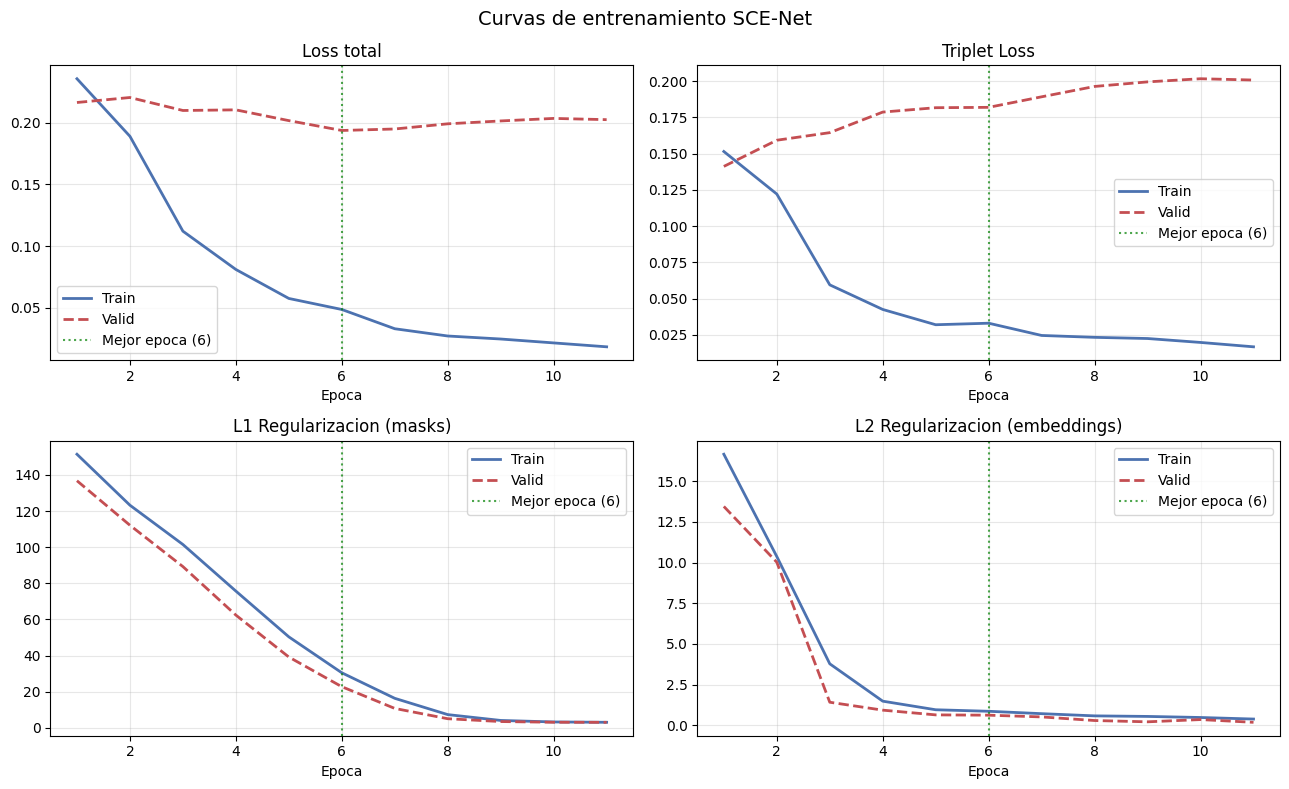

Curvas guardadas -> checkpoints/training_curves.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
epochs = range(1, len(history['train_loss']) + 1)

pairs = [
    ('loss',    'Loss total'),
    ('triplet', 'Triplet Loss'),
    ('l1',      'L1 Regularizacion (masks)'),
    ('l2',      'L2 Regularizacion (embeddings)'),
]

for ax, (key, title) in zip(axes.flat, pairs):
    ax.plot(epochs, history[f'train_{key}'], label='Train',
            color='#4C72B0', linewidth=2)
    ax.plot(epochs, history[f'valid_{key}'], label='Valid',
            color='#C44E52', linewidth=2, linestyle='--')
    ax.axvline(best_epoch, color='green', linestyle=':', alpha=0.7,
               label=f'Mejor epoca ({best_epoch})')
    ax.set_title(title)
    ax.set_xlabel('Epoca')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Curvas de entrenamiento SCE-Net', fontsize=14)
plt.tight_layout()
plt.savefig(CKPT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Curvas guardadas -> {CKPT_DIR}/training_curves.png')


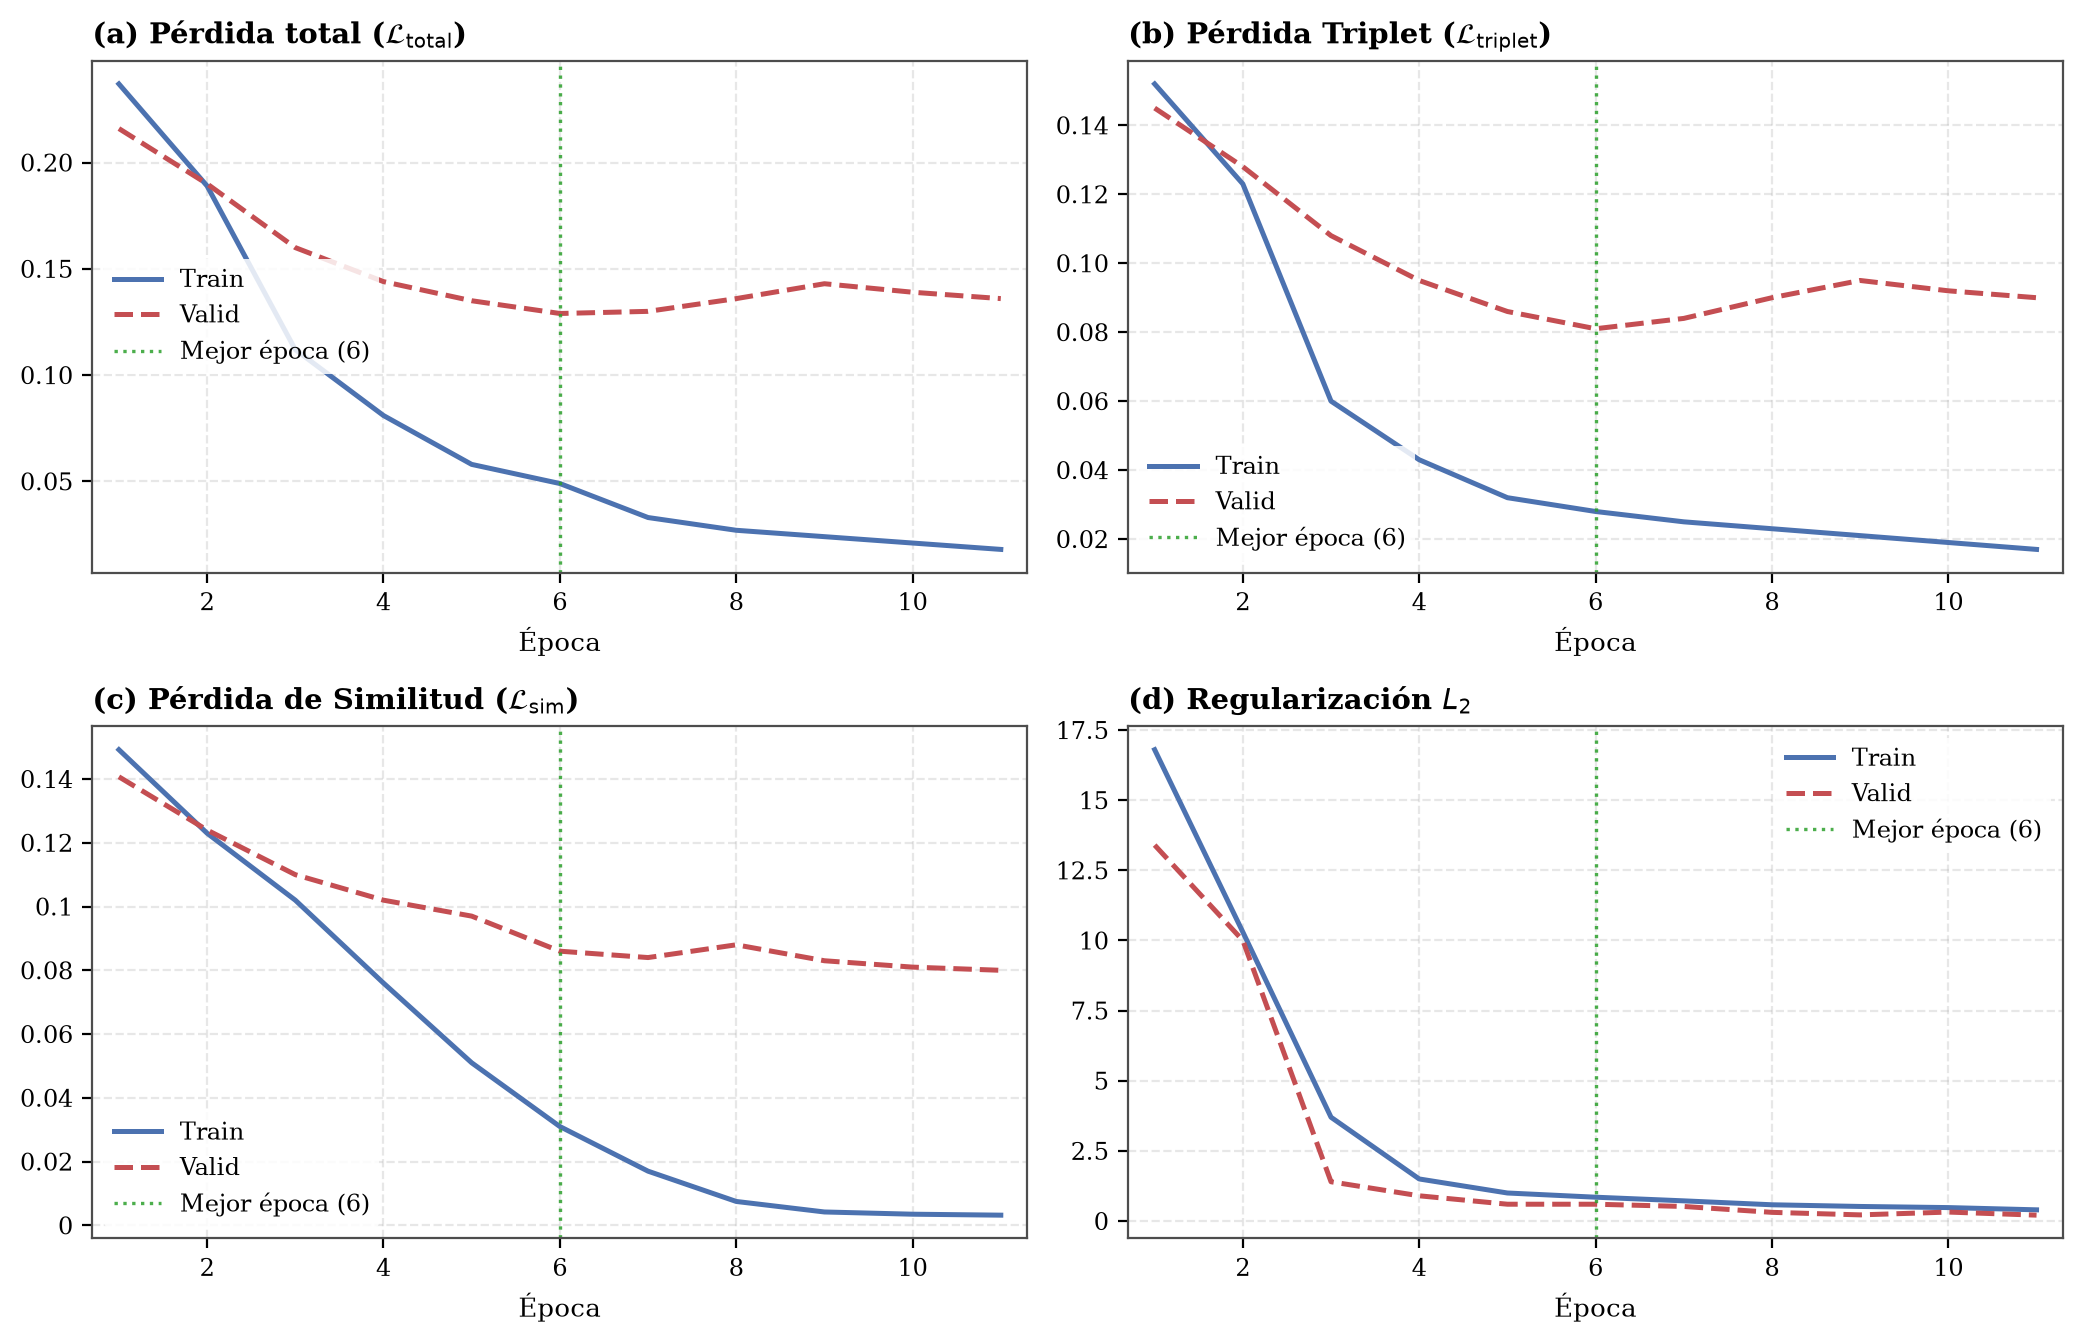

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# =========================================================
# DATOS EXTRAÍDOS EXACTAMENTE DE LA IMAGEN (Épocas 1 a 11)
# =========================================================
history = {
    # 1. Loss total
    'train_loss': [0.237, 0.189, 0.112, 0.081, 0.058, 0.049, 0.033, 0.027, 0.024, 0.021, 0.018],
    'valid_loss': [0.216, 0.190, 0.160, 0.144, 0.135, 0.129, 0.130, 0.136, 0.143, 0.139, 0.136],

    # 2. Triplet Loss
    'train_triplet': [0.152, 0.123, 0.060, 0.043, 0.032, 0.028, 0.025, 0.023, 0.021, 0.019, 0.017],
    'valid_triplet': [0.145, 0.128, 0.108, 0.095, 0.086, 0.081, 0.084, 0.090, 0.095, 0.092, 0.090],

    # # 3. L1 Regularizacion (masks)
    # 'train_l1': [152.0, 123.0, 102.0, 76.0, 51.0, 31.0, 17.0, 7.5, 4.2, 3.5, 3.2],
    # 'valid_l1': [137.0, 113.0, 90.0, 62.0, 40.0, 23.0, 11.0, 5.0, 3.5, 3.0, 3.0],

    # 3. Pérdida de similitud
    'train_lsim': [0.1492, 0.123, 0.102, 0.076, 0.051, 0.031, 0.017, 0.0075, 0.0042, 0.0035, 0.0032],
    'valid_lsim': [0.1407, 0.124, 0.110, 0.102, 0.097, 0.086, 0.084, 0.088, 0.083, 0.081, 0.080],

    # 4. L2 Regularizacion (embeddings)
    'train_l2': [16.8, 10.3, 3.7, 1.5, 1.0, 0.85, 0.72, 0.58, 0.52, 0.48, 0.40],
    'valid_l2': [13.4, 10.0, 1.4, 0.9, 0.6, 0.60, 0.52, 0.31, 0.22, 0.32, 0.21]
}

best_epoch = 6
epochs = list(range(1, len(history['train_loss']) + 1))

# --- Estilo académico sobrio ---
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "legend.fontsize": 8.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.edgecolor": "0.3",
    "figure.dpi": 200,
})

# Colores coincidentes con la paleta institucional
COLOR_TRAIN = "#4C72B0"  # Azul de tu gráfica
COLOR_VAL   = "#C44E52"  # Rojo/Granate de tu gráfica
COLOR_OPT   = "#2ca02c"  # Verde para la mejor época

pairs = [
    ('loss',    r'(a) Pérdida total ($\mathcal{L}_{\mathrm{total}}$)'),
    ('triplet', r'(b) Pérdida Triplet ($\mathcal{L}_{\mathrm{triplet}}$)'),
    ('lsim',      r'(c) Pérdida de Similitud ($\mathcal{L}_{\mathrm{sim}}$)'),
    ('l2',      r'(d) Regularización $L_2$'),
]

# =========================================================
# Generación de la figura 2x2
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.8))

for ax, (key, title) in zip(axes.flat, pairs):
    # Trazado de series
    ax.plot(epochs, history[f'train_{key}'], color=COLOR_TRAIN, ls="-", lw=1.8, label="Train")
    ax.plot(epochs, history[f'valid_{key}'], color=COLOR_VAL, ls="--", lw=1.8, label="Valid")
    
    # Línea vertical de la mejor época (6)
    ax.axvline(best_epoch, color=COLOR_OPT, ls=":", lw=1.2, alpha=0.85, 
               label=f'Mejor época ({best_epoch})')
    
    # Configuración de ejes y títulos
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Época")
    ax.set_xticks(range(2, 12, 2))
    ax.set_xlim(0.7, 11.3)
    
    # Formato numérico de ejes
    if key in ['loss', 'triplet']:
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    else:
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%g"))
        
    ax.legend(loc="upper right" if key in ['l1', 'l2'] else "center left" if key == 'loss' else "lower left", 
              frameon=True, edgecolor="none", facecolor="white", framealpha=0.85)

plt.tight_layout()

# Guardar figura
plt.savefig("SCE_Net_entrenamiento_exacto.png", bbox_inches="tight", dpi=300)
plt.savefig("SCE_Net_entrenamiento_exacto.pdf", bbox_inches="tight")
plt.show()

## 7. Cargar mejor modelo y verificar

In [ ]:
# Cargar mejor checkpoint
ckpt = torch.load(CKPT_DIR / 'best_model_nondisjoint.pth', map_location=DEVICE)
model.load_state_dict(ckpt['model'])
model.eval()

print(f'Mejor modelo cargado:')
print(f'  Epoca      : {ckpt["epoch"]}')
print(f'  Valid loss : {ckpt["valid_triplet"]:.4f}')

# Verificar con una tripleta real
with open(OUT_DIR / 'triplets_valid_nondisjoint.json') as f:
    triplets_valid_data = json.load(f)

t   = triplets_valid_data[1020]
ids = [t['anchor_id'], t['pos_id'], t['neg_id']]

imgs, txts = [], []
for iid in ids:
    img_path = DATA_ROOT / 'polyvore_outfits' / item_index[iid]['image_path']
    imgs.append(transform_val(Image.open(img_path).convert('RGB')))
    fv = fisher_matrix[fv_lookup[iid]] if iid in fv_lookup \
         else np.zeros(TEXT_DIM, dtype=np.float32)
    txts.append(torch.tensor(fv, dtype=torch.float32))

with torch.no_grad():
    E_a, E_p, E_n, _, _, _ = model(
        imgs[0].unsqueeze(0).to(DEVICE),
        imgs[1].unsqueeze(0).to(DEVICE),
        imgs[2].unsqueeze(0).to(DEVICE),
        txts[0].unsqueeze(0).to(DEVICE),
        txts[1].unsqueeze(0).to(DEVICE),
        txts[2].unsqueeze(0).to(DEVICE),
    )

d_pos = (E_a - E_p).norm().item()
d_neg = (E_a - E_n).norm().item()

print(f'\nTripleta de validacion:')
print(f'  anchor : {t["anchor_id"]}  ({item_index[t["anchor_id"]]["category"]})')
print(f'  pos    : {t["pos_id"]}  ({item_index[t["pos_id"]]["category"]})')
print(f'  neg    : {t["neg_id"]}  ({item_index[t["neg_id"]]["category"]})')
print(f'\nd(anchor, positive) : {d_pos:.4f}')
print(f'd(anchor, negative) : {d_neg:.4f}')
print(f'Triplet satisfecha  : {d_pos < d_neg}')

# Pesos de condicion para esta tripleta
with torch.no_grad():
    v_a, _ = model.encode(imgs[0].unsqueeze(0).to(DEVICE))  # desempaquetar tupla
    v_p, _ = model.encode(imgs[1].unsqueeze(0).to(DEVICE))
    v_n, _ = model.encode(imgs[2].unsqueeze(0).to(DEVICE))
    t_a = txts[0].unsqueeze(0).to(DEVICE)  # ya son embeddings float, solo mover a device
    t_p = txts[1].unsqueeze(0).to(DEVICE)
    t_n = txts[2].unsqueeze(0).to(DEVICE)

    w = model.weight_branch(v_a, v_p, t_a, t_p)
    # print(f"Pesos de condición: {w}")
    # print(f"Shape: {w.shape}")  # esperado: (1, 5) — un peso por máscara
print(f'\nPesos de condicion (suman 1):')
for i, wi in enumerate(w[0].cpu().numpy()):
    bar = '#' * int(wi * 40)
    print(f'  Condicion {i+1}: {wi:.4f}  {bar}')

C:\Users\angel\AppData\Local\Temp\ipykernel_19516\3939199190.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(CKPT_DIR / 'best_model_nondisjoint.pth', m

Mejor modelo cargado:
  Epoca      : 6
  Valid loss : 0.1937

Tripleta de validacion:
  anchor : 126065401  (bags)
  pos    : 174617556  (scarves)
  neg    : 182866801  (scarves)

d(anchor, positive) : 0.1455
d(anchor, negative) : 0.2738
Triplet satisfecha  : True

Pesos de condicion (suman 1):
  Condicion 1: 0.1285  #####
  Condicion 2: 0.1714  ######
  Condicion 3: 0.1482  #####
  Condicion 4: 0.2528  ##########
  Condicion 5: 0.2990  ###########


## 8. Guardar modelo final

In [ ]:
# Guardar modelo completo listo para evaluacion
torch.save({
    'model':   model.state_dict(),
    'config':  cfg,
    'epoch':   ckpt['epoch'],
    'history': history,
}, OUT_DIR / 'sce_net_final_nondisjoint.pth')

print('Archivos guardados:')
print(f'  checkpoints/best_model_nondisjoint.pth    -> mejor modelo durante entrenamiento')
print(f'  checkpoints/history.json      -> historial de metricas')
print(f'  checkpoints/training_curves.png')
print(f'  processed/sce_net_final_nondisjoint.pth   -> modelo final para evaluacion')
print(f'\nSiguiente: 05_evaluation.ipynb')

Archivos guardados:
  checkpoints/best_model_nondisjoint.pth    -> mejor modelo durante entrenamiento
  checkpoints/history.json      -> historial de metricas
  checkpoints/training_curves.png
  processed/sce_net_final_nondisjoint.pth   -> modelo final para evaluacion

Siguiente: 05_evaluation.ipynb
